In [1]:
%pip install -q qiskit qiskit-aer qiskit-ibm-runtime scipy matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 3.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.


In [2]:

import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import differential_evolution
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# --------------------------------------------------
# 1. Cost Hamiltonian: Pauli decomposition
# Hc = (-I + Z0+Z1+Z2 - Z0Z1-Z0Z2-Z1Z2
#       + Z0Z1Z2)/8
# Identity term omitted (global phase only).
# --------------------------------------------------

PAULI_TERMS = [
    ((0,), 1/8),
    ((1,), 1/8),
    ((2,), 1/8),
    ((0, 1), -1/8),
    ((0, 2), -1/8),
    ((1, 2), -1/8),
    ((0, 1, 2), 1/8),
]

def apply_z_string(qc, qubits, theta):
    """
    Implements exp(-i theta/2 * product(Z_i)).
    """
    target = qubits[-1]

    # Compute parity
    for j in range(len(qubits) - 1):
        qc.cx(qubits[j], qubits[j + 1])

    qc.rz(theta, target)

    # Uncompute parity
    for j in reversed(range(len(qubits) - 1)):
        qc.cx(qubits[j], qubits[j + 1])

def apply_cost_pauli(qc, gamma):
    for qubits, coefficient in PAULI_TERMS:
        apply_z_string(qc, qubits, 2 * gamma * coefficient)

# --------------------------------------------------
# 2. Toffoli-based Cost Hamiltonian
# --------------------------------------------------

def apply_cost_toffoli(qc, gamma):
    # Ancilla is q3, initially |0>
    qc.ccx(0, 1, 3)

    # Apply phase only when x0=x1=x2=1
    qc.cp(gamma, 3, 2)

    # Restore ancilla to |0>
    qc.ccx(0, 1, 3)

# --------------------------------------------------
# 3. QAOA circuit (p = 1)
# --------------------------------------------------

def build_qaoa(gamma, beta, method="pauli"):
    n = 3 if method == "pauli" else 4
    qc = QuantumCircuit(n)

    # Initial superposition on data qubits
    for q in range(3):
        qc.h(q)

    qc.barrier()

    if method == "pauli":
        apply_cost_pauli(qc, gamma)
    elif method == "toffoli":
        apply_cost_toffoli(qc, gamma)
    else:
        raise ValueError("method must be pauli or toffoli")

    qc.barrier()

    # Mixer Hamiltonian: X0 + X1 + X2
    for q in range(3):
        qc.rx(2 * beta, q)

    return qc

# Show circuits
gamma_example = 1.0
beta_example = 0.5

qc_pauli = build_qaoa(gamma_example, beta_example, "pauli")
qc_toffoli = build_qaoa(gamma_example, beta_example, "toffoli")

print("=== Pauli decomposition circuit ===")
print(qc_pauli.draw("text"))

print("\n=== Toffoli circuit ===")
print(qc_toffoli.draw("text"))

=== Pauli decomposition circuit ===
     ┌───┐ ░ ┌──────────┐                                                   »
q_0: ┤ H ├─░─┤ Rz(0.25) ├──■─────────────────■────■─────────────────■───────»
     ├───┤ ░ ├──────────┤┌─┴─┐┌───────────┐┌─┴─┐  │                 │       »
q_1: ┤ H ├─░─┤ Rz(0.25) ├┤ X ├┤ Rz(-0.25) ├┤ X ├──┼─────────────────┼────■──»
     ├───┤ ░ ├──────────┤└───┘└───────────┘└───┘┌─┴─┐┌───────────┐┌─┴─┐┌─┴─┐»
q_2: ┤ H ├─░─┤ Rz(0.25) ├───────────────────────┤ X ├┤ Rz(-0.25) ├┤ X ├┤ X ├»
     └───┘ ░ └──────────┘                       └───┘└───────────┘└───┘└───┘»
«                                                        ░ ┌───────┐
«q_0: ────────────────────■──────────────────────────■───░─┤ Rx(1) ├
«                       ┌─┴─┐                      ┌─┴─┐ ░ ├───────┤
«q_1: ───────────────■──┤ X ├──■────────────────■──┤ X ├─░─┤ Rx(1) ├
«     ┌───────────┐┌─┴─┐└───┘┌─┴─┐┌──────────┐┌─┴─┐└───┘ ░ ├───────┤
«q_2: ┤ Rz(-0.25) ├┤ X ├─────┤ X ├┤ Rz(0.25) ├┤ X ├──────░─┤ Rx(1) ├
«   

In [3]:

def probability_111(gamma, beta, method):
    qc = build_qaoa(gamma, beta, method)
    sv = Statevector.from_instruction(qc)

    probs = sv.probabilities()

    # Both circuits: data state 111 has integer index 7.
    # In Toffoli circuit the ancilla is q3 and remains 0.
    return float(probs[7])

def objective(params):
    gamma, beta = params
    return -probability_111(gamma, beta, "pauli")

result = differential_evolution(
    objective,
    bounds=[(0, 2*np.pi), (0, np.pi)],
    seed=42,
    tol=1e-10
)

gamma_opt, beta_opt = result.x

print("Optimal gamma:", round(gamma_opt, 6))
print("Optimal beta :", round(beta_opt, 6))

for method in ["pauli", "toffoli"]:
    p111 = probability_111(gamma_opt, beta_opt, method)
    print(f"{method:8s} P(111) = {p111:.6f}")
    print(f"{method:8s} <Hc>   = {-p111:.6f}")

# Verify mathematical equivalence
qc1 = build_qaoa(gamma_opt, beta_opt, "pauli")
qc2 = build_qaoa(gamma_opt, beta_opt, "toffoli")

p1 = Statevector.from_instruction(qc1).probabilities()
p2 = Statevector.from_instruction(qc2).probabilities()

print("Equivalent distributions:",
      np.allclose(p1, p2[:8], atol=1e-10))

Optimal gamma: 4.157084
Optimal beta : 0.507745
pauli    P(111) = 0.424474
pauli    <Hc>   = -0.424474
toffoli  P(111) = 0.424474
toffoli  <Hc>   = -0.424474
Equivalent distributions: True


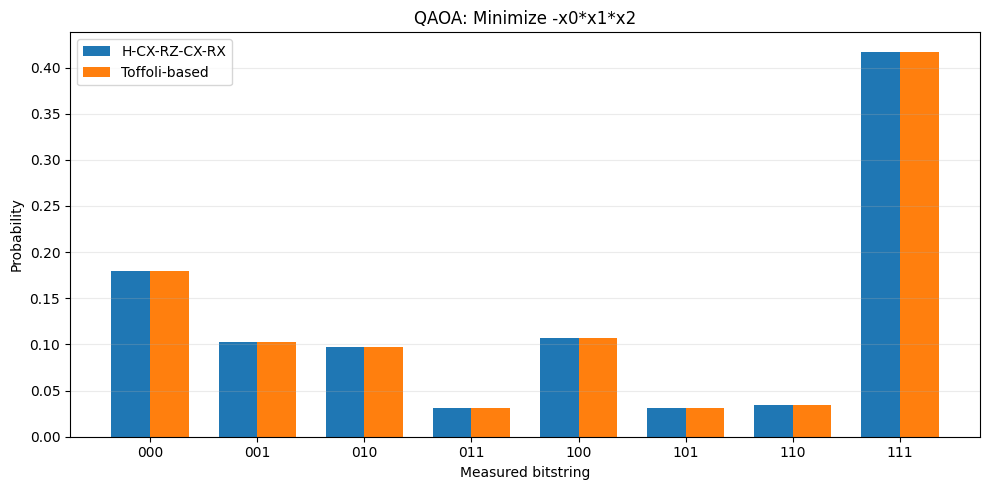

Pauli counts: {'111': 1709, '100': 436, '000': 736, '010': 400, '001': 421, '110': 141, '011': 127, '101': 126}
Toffoli counts: {'111': 1709, '100': 436, '000': 736, '010': 400, '001': 421, '110': 141, '011': 127, '101': 126}
Pauli P(111): 0.417236328125
Toffoli P(111): 0.417236328125


In [4]:

from qiskit.primitives import StatevectorSampler

shots = 4096
sampler = StatevectorSampler(default_shots=shots, seed=42)

def sample_qaoa(method):
    qc = build_qaoa(gamma_opt, beta_opt, method)

    # Measure only the three data qubits
    qc.measure_all()

    job = sampler.run([qc])
    result = job.result()[0]

    raw_counts = result.data.meas.get_counts()

    # In the 4-qubit Toffoli circuit, ancilla q3 is the
    # leftmost displayed bit and should always be 0.
    if method == "toffoli":
        counts = {}
        for key, count in raw_counts.items():
            data_bits = key[-3:]
            counts[data_bits] = counts.get(data_bits, 0) + count
    else:
        counts = raw_counts

    return counts

counts_pauli = sample_qaoa("pauli")
counts_toffoli = sample_qaoa("toffoli")

states = [format(i, "03b") for i in range(8)]

pauli_probs = [
    counts_pauli.get(s, 0) / shots for s in states
]
toffoli_probs = [
    counts_toffoli.get(s, 0) / shots for s in states
]

x = np.arange(8)
width = 0.36

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, pauli_probs, width,
        label="H-CX-RZ-CX-RX")
plt.bar(x + width/2, toffoli_probs, width,
        label="Toffoli-based")

plt.xticks(x, states)
plt.xlabel("Measured bitstring")
plt.ylabel("Probability")
plt.title("QAOA: Minimize -x0*x1*x2")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("Pauli counts:", counts_pauli)
print("Toffoli counts:", counts_toffoli)

print("Pauli P(111):",
      counts_pauli.get("111", 0) / shots)
print("Toffoli P(111):",
      counts_toffoli.get("111", 0) / shots)

In [10]:

from qiskit_ibm_runtime import (
    QiskitRuntimeService,
    SamplerV2 as Sampler
)
from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)

# IBM Quantum credentials must already be configured.
service = QiskitRuntimeService()

backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=4
)

print("Selected backend:", backend.name)

def run_on_ibm(method):
    qc = build_qaoa(gamma_opt, beta_opt, method)
    qc.measure_all()

    # Convert gates to instructions supported by the QPU
    pm = generate_preset_pass_manager(
        backend=backend,
        optimization_level=2
    )
    isa_circuit = pm.run(qc)

    print(method, "depth:", isa_circuit.depth())
    print(method, "operations:", isa_circuit.count_ops())

    sampler = Sampler(mode=backend)
    job = sampler.run([isa_circuit], shots=4096)

    print("Job ID:", job.job_id())

    result = job.result()
    counts = result[0].data.meas.get_counts()

    if method == "toffoli":
        data_counts = {}
        for bits, count in counts.items():
            key = bits[-3:]
            data_counts[key] = data_counts.get(key, 0) + count
        counts = data_counts

    print(method, "counts:", counts)
    print(method, "P(111):",
          counts.get("111", 0) / 4096)

    return counts, isa_circuit

# Run both approaches on IBM QPU
ibm_pauli, isa_pauli = run_on_ibm("pauli")
ibm_toffoli, isa_toffoli = run_on_ibm("toffoli")

AccountNotFoundError: "Unable to find account. Please make sure an account with the channel name 'ibm_quantum_platform' is saved."

In [9]:
from qiskit_ibm_runtime import QiskitRuntimeService
from getpass import getpass

# 인증 정보 입력 (화면에 표시되지 않음)
api_key = getpass("IBM Quantum API Key: ")
instance_crn = input("IBM Quantum Instance CRN: ").strip()

# IBM Quantum 연결
service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=api_key,
    instance=instance_crn if instance_crn else "auto"
)

print("IBM Quantum 연결 성공!")

# 이용 가능한 양자컴퓨터 목록
backends = service.backends(
    operational=True,
    simulator=False
)

for backend in backends:
    print(backend.name)

IBM Quantum API Key: ··········
IBM Quantum Instance CRN: crn:v1:bluemix:public:quantum-computing:us-east:a/1decc8fd87744358800acb637b74685f:cd3d1d66-dae7-4b95-9b52-3112cf0be46d::


qiskit_runtime_service._discover_account:WARNING:2026-11-23 00:31:35,042: Loading account with the given token. A saved account will not be used.


IBM Quantum 연결 성공!
ibm_fez
ibm_kingston
ibm_marrakesh


In [11]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy.optimize import differential_evolution
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler

print("Libraries loaded successfully!")


Libraries loaded successfully!


In [12]:

# Cost Hamiltonian:
# Hc = (-I + Z0 + Z1 + Z2
#       - Z0Z1 - Z0Z2 - Z1Z2
#       + Z0Z1Z2) / 8

pauli_terms = [
    ([0], 1/8),
    ([1], 1/8),
    ([2], 1/8),
    ([0, 1], -1/8),
    ([0, 2], -1/8),
    ([1, 2], -1/8),
    ([0, 1, 2], 1/8)
]

def apply_pauli_cost(qc, gamma):
    for qubits, coeff in pauli_terms:
        for i in range(len(qubits) - 1):
            qc.cx(qubits[i], qubits[i + 1])

        qc.rz(2 * gamma * coeff, qubits[-1])

        for i in reversed(range(len(qubits) - 1)):
            qc.cx(qubits[i], qubits[i + 1])


def build_pauli_qaoa(gamma, beta):
    qc = QuantumCircuit(3, 3)

    # Hadamard: superposition
    qc.h([0, 1, 2])
    qc.barrier()

    # Cost Hamiltonian
    apply_pauli_cost(qc, gamma)
    qc.barrier()

    # Mixer Hamiltonian
    for q in range(3):
        qc.rx(2 * beta, q)

    return qc


def build_toffoli_qaoa(gamma, beta):
    # 3 data qubits + 1 ancilla
    qc = QuantumCircuit(4, 3)

    qc.h([0, 1, 2])
    qc.barrier()

    # Toffoli: compute x0 AND x1
    qc.ccx(0, 1, 3)

    # Conditional phase for x0=x1=x2=1
    qc.cp(gamma, 3, 2)

    # Uncompute ancilla
    qc.ccx(0, 1, 3)
    qc.barrier()

    # Mixer
    for q in range(3):
        qc.rx(2 * beta, q)

    return qc


print("Both QAOA circuits created!")


Both QAOA circuits created!


In [13]:

def get_prob_111(gamma, beta):
    qc = build_pauli_qaoa(gamma, beta)

    sv = Statevector.from_instruction(
        qc.remove_final_measurements(inplace=False)
    )

    return float(sv.probabilities()[7])


def objective(params):
    gamma, beta = params
    return -get_prob_111(gamma, beta)


result = differential_evolution(
    objective,
    bounds=[(0, 2*np.pi), (0, np.pi)],
    seed=42,
    tol=1e-10
)

gamma_opt, beta_opt = result.x

print("Optimal gamma =", round(gamma_opt, 6))
print("Optimal beta  =", round(beta_opt, 6))
print("Optimal P(111) =", round(-result.fun, 6))
print("Expected energy =", round(result.fun, 6))

# Verify that both circuits produce the same distribution
p_circuit = build_pauli_qaoa(gamma_opt, beta_opt)
t_circuit = build_toffoli_qaoa(gamma_opt, beta_opt)

p_sv = Statevector.from_instruction(
    p_circuit.remove_final_measurements(inplace=False)
)
t_sv = Statevector.from_instruction(
    t_circuit.remove_final_measurements(inplace=False)
)

assert np.allclose(
    p_sv.probabilities(),
    t_sv.probabilities()[:8],
    atol=1e-10
)

print("Pauli / Toffoli equivalence verified!")


Optimal gamma = 4.157084
Optimal beta  = 0.507745
Optimal P(111) = 0.424474
Expected energy = -0.424474
Pauli / Toffoli equivalence verified!


In [15]:

# Select actual IBM quantum hardware
backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=4
)

print("Selected IBM QPU:", backend.name)

# Add measurements for data qubits only
qc_pauli = build_pauli_qaoa(gamma_opt, beta_opt)
qc_pauli.measure([0, 1, 2], [0, 1, 2])

qc_toffoli = build_toffoli_qaoa(gamma_opt, beta_opt)
qc_toffoli.measure([0, 1, 2], [0, 1, 2])

# Transpile for IBM hardware
pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=2,
    seed_transpiler=42
)

isa_pauli = pm.run(qc_pauli)
isa_toffoli = pm.run(qc_toffoli)

print("\n--- Circuit resource comparison ---")
print("Pauli depth:", isa_pauli.depth())
print("Toffoli depth:", isa_toffoli.depth())

print("Pauli operations:", isa_pauli.count_ops())
print("Toffoli operations:", isa_toffoli.count_ops())

# Execute both in a single job
sampler = Sampler(mode=backend)

shots = 4096

job = sampler.run(
    [isa_pauli, isa_toffoli],
    shots=shots
)

print("\nIBM Quantum Job submitted!")
print("Job ID:", job.job_id())

# Retrieve results
hardware_result = job.result()

counts_pauli = hardware_result[0].data.c.get_counts()
counts_toffoli = hardware_result[1].data.c.get_counts()

print("\n=== Actual IBM Quantum Results ===")
print("Pauli counts:", counts_pauli)
print("Toffoli counts:", counts_toffoli)


Selected IBM QPU: ibm_marrakesh

--- Circuit resource comparison ---
Pauli depth: 51
Toffoli depth: 78
Pauli operations: OrderedDict({'rz': 32, 'sx': 30, 'cz': 13, 'measure': 3, 'barrier': 2})
Toffoli operations: OrderedDict({'sx': 47, 'rz': 45, 'cz': 21, 'measure': 3, 'barrier': 2})

IBM Quantum Job submitted!
Job ID: dc1ojruq4uuc73a47dc0

=== Actual IBM Quantum Results ===
Pauli counts: {'111': 1529, '011': 163, '010': 482, '101': 137, '110': 209, '000': 745, '100': 412, '001': 419}
Toffoli counts: {'000': 678, '010': 414, '001': 503, '111': 1328, '100': 431, '011': 353, '101': 183, '110': 206}


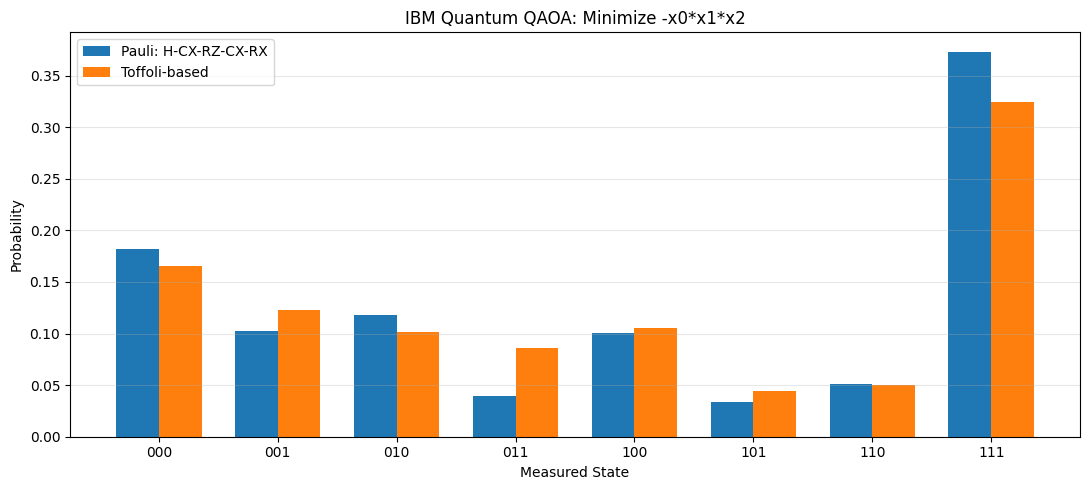

In [16]:

states = [format(i, "03b") for i in range(8)]

pauli_prob = np.array([
    counts_pauli.get(s, 0) / shots
    for s in states
])

toffoli_prob = np.array([
    counts_toffoli.get(s, 0) / shots
    for s in states
])

x = np.arange(8)
width = 0.36

plt.figure(figsize=(11, 5))

plt.bar(
    x - width/2,
    pauli_prob,
    width,
    label="Pauli: H-CX-RZ-CX-RX"
)

plt.bar(
    x + width/2,
    toffoli_prob,
    width,
    label="Toffoli-based"
)

plt.xticks(x, states)
plt.xlabel("Measured State")
plt.ylabel("Probability")
plt.title("IBM Quantum QAOA: Minimize -x0*x1*x2")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("IBM_QAOA_Result.png", dpi=300)
plt.show()


In [17]:

ideal_p111 = get_prob_111(gamma_opt, beta_opt)

p111_pauli = counts_pauli.get("111", 0) / shots
p111_toffoli = counts_toffoli.get("111", 0) / shots

comparison = pd.DataFrame({
    "Method": [
        "Pauli Decomposition",
        "Toffoli Gate"
    ],
    "Qubits": [3, 4],
    "Circuit Depth": [
        isa_pauli.depth(),
        isa_toffoli.depth()
    ],
    "P(111) (%)": [
        100 * p111_pauli,
        100 * p111_toffoli
    ],
    "Expected Energy": [
        -p111_pauli,
        -p111_toffoli
    ]
})

print("IBM Quantum Hardware Comparison")
display(comparison.round(4))

print("\nIdeal P(111):", round(ideal_p111, 6))
print("Pauli P(111):", round(p111_pauli, 6))
print("Toffoli P(111):", round(p111_toffoli, 6))

print("\nResult difference (%p):",
      round(100 * abs(p111_pauli - p111_toffoli), 4))

comparison.to_csv(
    "IBM_QAOA_Comparison.csv",
    index=False
)

print("Results saved!")


IBM Quantum Hardware Comparison


,Method,Qubits,Circuit Depth,P(111) (%),Expected Energy
0,Pauli Decomposition,3,51,37.3291,-0.3733
1,Toffoli Gate,4,78,32.4219,-0.3242



Ideal P(111): 0.424474
Pauli P(111): 0.373291
Toffoli P(111): 0.324219

Result difference (%p): 4.9072
Results saved!


In [18]:
print("=== Pauli Decomposition ===")
print("Depth:", isa_pauli.depth())
print("Operations:", isa_pauli.count_ops())

print("\n=== Toffoli Approach ===")
print("Depth:", isa_toffoli.depth())
print("Operations:", isa_toffoli.count_ops())

=== Pauli Decomposition ===
Depth: 51
Operations: OrderedDict({'rz': 32, 'sx': 30, 'cz': 13, 'measure': 3, 'barrier': 2})

=== Toffoli Approach ===
Depth: 78
Operations: OrderedDict({'sx': 47, 'rz': 45, 'cz': 21, 'measure': 3, 'barrier': 2})
